![Johnson & Johnson MedTech Logo](https://raw.githubusercontent.com/Forage-Simulations/Johnson-Johnson-Robotics-Controls/main/github_assets.png)


# Robotic Arm Design Simulation

### Objective
This notebook helps simulate the impact of design modifications on a robotic arm’s performance. You will:

- Test design modifications for improving response time and durability.
- Input efficiency and reinforcement factors to assess their impact.
- Visualize simulation results for response time and durability metrics.
- Document findings to support your design proposal.

### Instructions
1. **Run Setup Cells**: Load libraries and define functions necessary for simulations.
2. **Input Factors**: Enter efficiency and reinforcement factors to simulate improvements.
3. **Analyze Results**: Compare original and improved metrics using the visual output.
4. **Document Findings**: Record your observations to support your design proposal.

Ensure you use the **Design Proposal Template** to document your findings.


In [1]:
# Import required libraries
import numpy as np  # For numerical calculations
import matplotlib.pyplot as plt  # For data visualization

# Ensure the necessary libraries are installed
try:
    import numpy
    import matplotlib
except ImportError as e:
    print(f"Missing library: {e}. Please install it using 'pip install numpy matplotlib'.")


In [2]:
# Function to simulate response time improvements
def simulate_response_time(base_time, efficiency_factor):
    """Calculate the new response time based on efficiency improvements."""
    return base_time * (1 - efficiency_factor)

# Function to simulate durability improvements
def simulate_durability(base_durability, reinforcement_factor):
    """Calculate the new durability score based on reinforcement."""
    return base_durability + (base_durability * reinforcement_factor)


In [3]:
# Example Base Metrics
base_response_time = 0.20  # in seconds
base_durability = 75       # durability score out of 100

# User Inputs with Validation
while True:
    try:
        efficiency_factor = float(input("Enter efficiency improvement factor (between 0 and 1, e.g., 0.15 for 15%): "))
        if 0 <= efficiency_factor <= 1:
            break
        else:
            print("Please enter a value between 0 and 1.")
    except ValueError:
        print("Invalid input. Please enter a numerical value.")

while True:
    try:
        reinforcement_factor = float(input("Enter durability reinforcement factor (between 0 and 1, e.g., 0.10 for 10%): "))
        if 0 <= reinforcement_factor <= 1:
            break
        else:
            print("Please enter a value between 0 and 1.")
    except ValueError:
        print("Invalid input. Please enter a numerical value.")


Enter efficiency improvement factor (between 0 and 1, e.g., 0.15 for 15%): 0.15
Enter durability reinforcement factor (between 0 and 1, e.g., 0.10 for 10%): 0.10


In [4]:
# Simulations
new_response_time = simulate_response_time(base_response_time, efficiency_factor)
new_durability = simulate_durability(base_durability, reinforcement_factor)

# Output Results
print("\nSimulation Results:")
print(f"Original Response Time: {base_response_time} seconds")
print(f"New Response Time: {round(new_response_time, 3)} seconds")
print(f"Original Durability Score: {base_durability}")
print(f"New Durability Score: {round(new_durability, 2)}")



Simulation Results:
Original Response Time: 0.2 seconds
New Response Time: 0.17 seconds
Original Durability Score: 75
New Durability Score: 82.5


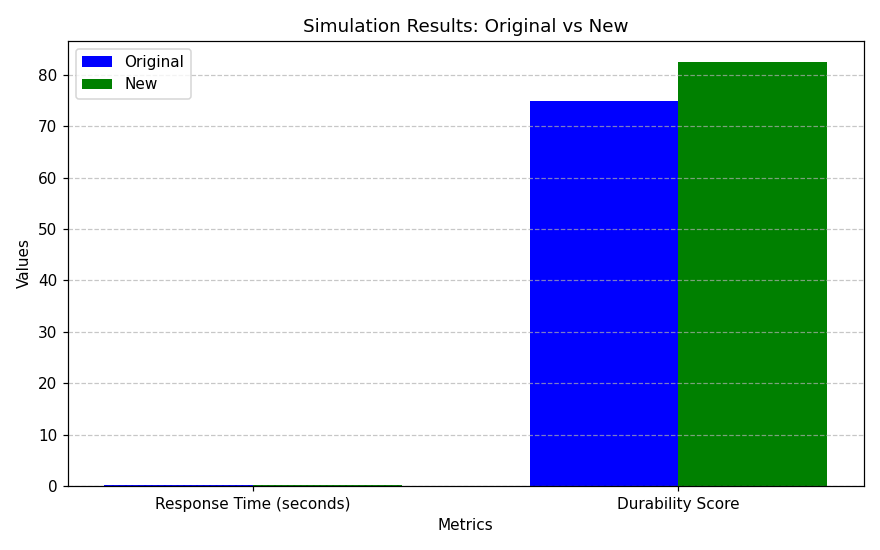

In [5]:
# Visual Feedback
metrics = ["Response Time (seconds)", "Durability Score"]
original_values = [base_response_time, base_durability]
new_values = [new_response_time, new_durability]

plt.figure(figsize=(8, 5))
x = np.arange(len(metrics))
width = 0.35

plt.bar(x - width/2, original_values, width, label='Original', color='blue')
plt.bar(x + width/2, new_values, width, label='New', color='green')

plt.xlabel("Metrics")
plt.ylabel("Values")
plt.title("Simulation Results: Original vs New")
plt.xticks(x, metrics)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


### Iterative Testing

Instead of trusting a single run, this cell tries three combinations of factors and checks each against two acceptance criteria (my own, chosen for this proposal):

1. Every command from the control diagnostics finishes at least 10% under its expected response time.
2. Durability improves by at least 10%.

In [6]:
# Iterative testing of efficiency and reinforcement factors
observed = {"move_arm": 0.102, "rotate_joint": 0.15, "adjust_grip": 0.051}   # from the diagnostics
expected = {"move_arm": 0.10, "rotate_joint": 0.18, "adjust_grip": 0.09}
trials = [(0.05, 0.05), (0.10, 0.10), (0.15, 0.10)]   # (efficiency, reinforcement)

obs = np.array(list(observed.values()))
exp = np.array(list(expected.values()))

print(f"{'Trial':<7}{'Eff.':>6}{'Reinf.':>8}{'Resp. (s)':>11}{'Durability':>12}{'Worst margin':>14}  Result")
for i, (eff, rein) in enumerate(trials, 1):
    resp = simulate_response_time(base_response_time, eff)
    dur = simulate_durability(base_durability, rein)
    worst_margin = ((exp - obs * (1 - eff)) / exp).min()
    passed = worst_margin >= 0.10 and (dur - base_durability) / base_durability >= 0.10 - 1e-9
    print(f"{i:<7}{eff:>6.2f}{rein:>8.2f}{resp:>11.3f}{dur:>12.2f}{worst_margin:>14.1%}  {'PASS' if passed else 'refine'}")


Trial    Eff.  Reinf.  Resp. (s)  Durability  Worst margin  Result
1        0.05    0.05      0.190       78.75          3.1%  refine
2        0.10    0.10      0.180       82.50          8.2%  refine
3        0.15    0.10      0.170       82.50         13.3%  PASS


### Observations and Results

Record your observations from the simulation below:

**Inputs tested:** efficiency improvement factor = 0.15 (15%), durability reinforcement factor = 0.10 (10%)

#### Initial Metrics:
- Response Time: 0.20 seconds
- Durability Score: 75

#### Improved Metrics:
- Response Time: 0.17 seconds
- Durability Score: 82.5

#### Key Insights:
1. **How did the efficiency improvement factor impact response time?** A 15% efficiency improvement cut the response time by 0.03 seconds (0.20 to 0.17). The simulation multiplies the base time by (1 - factor), so the time falls by exactly the percentage entered.
2. **How did the reinforcement factor affect durability?** A 10% reinforcement raised the durability score by 7.5 points (75 to 82.5), because the simulation adds the base score multiplied by the factor.
3. **Were there any trade-offs between responsiveness and durability?** Not in this simulation, because the two factors are calculated independently. In a real arm, extra reinforcement adds mass and can slow movement, so both changes should be tested together on the actual hardware.

4. **How did iterative testing refine the choice?** Three trials were run (see the Iterative Testing cell). Efficiency 0.05 and 0.10 left `move_arm` with only 3% and 8% margin under its expected time, so they were refined. Efficiency 0.15 with reinforcement 0.10 gave a 13% margin and a 10% durability gain, meeting both criteria while staying within the 10-15% range recommended for a first design.

#### Conclusion:
Upgrading the joint actuators (efficiency) and reinforcing the sensor mounts (durability) improved both metrics in the simulation: response time down 15% and durability up 10%. Because the simulation uses simple formulas and example base values, the next steps are to test on real hardware, measure the sensor feedback delay (which is not modelled here) and check that the added reinforcement does not slow the arm down.